# CS-781 Capstone - Phase 2 (L-NER): Experiment 3 - Houlsby bottleneck adapters implemented from scratch

**Idea (Houlsby et al., 2019).** Insert two small bottleneck MLPs into every Transformer block - one after the attention sub-layer, one after the feed-forward sub-layer, before the residual connection:
`h' = h + W_up( GELU( W_down h ) )` with `W_down: d -> m`, `W_up: m -> d` (zero-initialised, so the model starts unchanged). The backbone is frozen; adapters, RMSNorm scales and the NER head train.

Unlike LoRA/LoRMA this is an **additive-module** method: it cannot be merged into the weights and adds a little inference latency - a useful contrast for the report. Written from scratch in `peft_adapter.py`; bottleneck `m = 64`.

---

**Task (Phase 2, L-NER).** Predict `[start_char, end_char, label]` spans for 12 legal entity types; scored by **strict** macro-F1 (exact start, end and label).

**Pipeline implemented in `ner_lib.py` (written by the cell below, identical in all four notebooks):**
1. Load a **Phase-1 model** (`export_<arch>/` from your Phase-1 notebooks) - no other pretrained weights are used.
2. Documents are whitespace-normalised exactly like Phase-1 training, **with an offset map back to the original text**, tokenised with the Phase-1 byte-level BPE (which returns character offsets), and converted to **BIO token tags**.
   A built-in *oracle check* encodes the gold spans, decodes them again and must reproduce ~100% F1 - this catches every offset bug before you spend GPU time.
3. Long documents are cut into overlapping windows; at inference the per-token log-probabilities of overlapping windows are averaged (centre of a window weighted highest) and BIO tags are decoded into character spans.
4. **Decoder-only backbones** (GQA / MLA / RetNet) are causal, so each window is read twice (`[w, w]`) and the head reads the second copy - every token then sees the full window. The **enc-dec backbone** uses its bidirectional encoder directly (decoder dropped).
5. A linear token-classification head (25 BIO tags) is trained on top. Validation = document-level 15% hold-out of fold1+fold2 (no public dev set); the best epoch by validation strict macro-F1 is kept.

**Outputs:** `submission.zip` (with `prediction.json` at the root) for Codabench, `results.json` (metrics, params, speed for your report) and a `ner_export_*` folder that the distillation notebook can use as teacher.
Run order inside the notebook: top to bottom. To test another backbone, change `BACKBONE_ARCH` and re-run.

## 1. Hugging Face login

In [1]:
# Same as the starter: read the HF token from Kaggle secrets (secret name "HF"); falls back to env var / anonymous.
import os
HF_TOKEN = None
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    from huggingface_hub import login
    login(token=HF_TOKEN)
    print("Hugging Face login successful.")
else:
    print("No HF token found - continuing anonymously (works only if the dataset is public).")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. GPU

In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i), "| capability", torch.cuda.get_device_capability(i))

CUDA available: True
GPU 0: Tesla T4 | capability (7, 5)
GPU 1: Tesla T4 | capability (7, 5)


## 3. Configuration (which Phase-1 backbone, hyper-parameters)

In [3]:
import os, sys, json, math, time, random, glob, copy, importlib
from pathlib import Path
import numpy as np
import torch

# ------------------------------------------------------------------ WHICH PHASE-1 BACKBONE?
BACKBONE_ARCH = "mla"          # gqa | mla | encdec | retnet  (run this notebook once per backbone you want to test)
P1_EXPORT_DIR = "/kaggle/input/datasets/starvis05/export-mla"              # None -> auto-search /kaggle/input/**/export_<arch>/ ; or give the folder explicitly
NORMALIZE_WHITESPACE = True         # must match what the Phase-1 model was trained with (the Phase-1 notebooks used True)
METHOD = "adapter"

# ------------------------------------------------------------------ data / split
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
VAL_FRAC = 0.15                     # document-level held-out split of fold1+fold2 (no public dev set exists)
SEED = 42

# ------------------------------------------------------------------ optimisation
EPOCHS      = 8
LR          = 5e-4
HEAD_MULT   = 3.0          # the new classification head learns HEAD_MULT x faster than the adapters
BATCH, ACCUM = 8, 2
WD, WARMUP, GRAD_CLIP = 0.01, 0.06, 1.0
O_WEIGHT    = 1.0                   # class-balancing knob: weight of the 'O' (no entity) tag in the loss (try 0.3-0.5)

# ------------------------------------------------------------------ method hyper-parameters
MCFG_FACTORY = lambda: dict(bottleneck=64, train_norms=True, head_dropout=0.1)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
print("device:", device)

device: cuda


## 4. Library (`ner_lib.py`) and the from-scratch ADAPTER implementation (`peft_adapter.py`)

In [4]:
%%writefile ner_lib.py
"""Phase-2 (Legal NER) helper library: data alignment, BIO decoding, strict F1, training loop, export/load.
Everything PEFT-related (LoRA / LoRMA / adapters) lives in separate peft_*.py files and is written from scratch."""
import os, sys, re, json, math, time, glob, shutil, random, hashlib, importlib.util, contextlib
from collections import Counter
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ====================================================================== loading Phase-1 models
def load_module_from_file(path, name):
    spec = importlib.util.spec_from_file_location(name, str(path))
    mod = importlib.util.module_from_spec(spec)
    sys.modules[name] = mod                      # needed by @dataclass
    spec.loader.exec_module(mod)
    return mod


def file_hash(path):
    return hashlib.md5(open(path, "rb").read()).hexdigest()[:10]


def find_p1_export(arch, roots=("/kaggle/input", "/kaggle/working", ".")):
    hits = []
    for r in roots:
        hits += glob.glob(f"{r}/**/export_{arch}/config.json", recursive=True)
    return Path(hits[0]).parent if hits else None


def load_p1(export_dir):
    """Returns (arch_module, cfg_dict, backbone_with_phase1_weights)."""
    export_dir = Path(export_dir)
    cj = json.load(open(export_dir / "config.json"))
    mod = load_module_from_file(export_dir / "legal_arch.py",
                                f"legal_arch_{cj['arch']}_{file_hash(export_dir / 'legal_arch.py')}")
    bb = mod.build_model(mod.ArchConfig(**cj["cfg"]))
    bb.load_state_dict(torch.load(export_dir / "model.pt", map_location="cpu", weights_only=False))
    return mod, cj["cfg"], bb


def blocks_of(bb):
    return bb.blocks if bb.kind == "decoder" else bb.enc_blocks


def final_norm_of(bb):
    return bb.norm_f if bb.kind == "decoder" else bb.enc_norm


def strip_backbone(bb):
    """Keep only what NER needs: embeddings + decoder-only stack, or the ENCODER of the enc-dec model."""
    if bb.kind == "encdec":
        del bb.dec_blocks
        del bb.dec_norm
    bb.lm_head = nn.Identity()
    return bb


def replace_modules(bb, match, factory):
    n = 0
    for blk in blocks_of(bb):
        for name, mod in list(blk.named_modules()):
            if name and match(name, mod):
                parent_name, _, leaf = name.rpartition(".")
                parent = blk.get_submodule(parent_name) if parent_name else blk
                setattr(parent, leaf, factory(mod))
                n += 1
    return n


def replace_linears(bb, targets, factory):
    targets = set(targets)
    return replace_modules(bb, lambda n, m: isinstance(m, nn.Linear) and n.split(".")[-1] in targets, factory)


def load_peft(method, search_dirs=(".",)):
    for d in search_dirs:
        p = Path(d) / f"peft_{method}.py"
        if p.exists():
            return load_module_from_file(p, f"peft_{method}_{file_hash(p)}")
    raise FileNotFoundError(f"peft_{method}.py not found in {search_dirs}")


def count_params(m):
    tot = sum(p.numel() for p in m.parameters())
    tr = sum(p.numel() for p in m.parameters() if p.requires_grad)
    return tot, tr


# ====================================================================== NER model
class NERModel(nn.Module):
    """backbone (Phase-1 model, possibly with PEFT modules) + token-classification head (BIO tags).
    Decoder-only backbones are causal, so with echo=True the window is fed TWICE ([w, w]) and the head reads the
    second copy: every token then sees the whole window to its left (= the first copy) -> pseudo-bidirectional.
    The enc-dec backbone uses its bidirectional encoder directly."""

    def __init__(self, bb, num_labels, echo=True, head_dropout=0.1):
        super().__init__()
        self.bb = bb
        self.kind = bb.kind
        self.echo = bool(echo) and bb.kind == "decoder"
        self.head = nn.Sequential(nn.Dropout(head_dropout), nn.Linear(bb.cfg.d_model, num_labels))
        nn.init.normal_(self.head[1].weight, std=0.02)
        nn.init.zeros_(self.head[1].bias)

    def features(self, x):
        if self.kind == "encdec":
            return self.bb.encode(x)
        if self.echo:
            return self.bb.hidden(torch.cat([x, x], dim=1))[:, x.size(1):]
        return self.bb.hidden(x)

    def forward(self, x):
        return self.head(self.features(x))


def assemble(bb, num_labels, method, mcfg, echo, peft_mod=None):
    """Turns a Phase-1 backbone into a NER model. method: 'full' | name of a peft_*.py module."""
    strip_backbone(bb)
    if method != "full":
        for p in bb.parameters():
            p.requires_grad = False
        peft_mod.apply(bb, mcfg)
    return NERModel(bb, num_labels, echo=echo, head_dropout=mcfg.get("head_dropout", 0.1))


def make_student_bb(mod, cfg, full_bb, keep):
    """Smaller student initialised from Phase-1 weights: keep only the layers listed in `keep` (embeddings shared)."""
    cfg = dict(cfg)
    if full_bb.kind == "decoder":
        cfg["n_layers"] = len(keep)
    else:
        cfg["n_enc_layers"] = len(keep)
        cfg["n_dec_layers"] = 1
    st = mod.build_model(mod.ArchConfig(**cfg))
    st.tok_emb.load_state_dict(full_bb.tok_emb.state_dict())
    final_norm_of(st).load_state_dict(final_norm_of(full_bb).state_dict())
    for i, j in enumerate(keep):
        blocks_of(st)[i].load_state_dict(blocks_of(full_bb)[j].state_dict())
    return st, cfg


# ====================================================================== data parsing
def parse_texts(obj):
    if isinstance(obj, dict):
        return {str(k): (v if isinstance(v, str) else v.get("text", "")) for k, v in obj.items()}
    return {str(it.get("id", it.get("doc_id"))): it["text"] for it in obj}


def _ent(e):
    if isinstance(e, (list, tuple)):
        return int(e[0]), int(e[1]), str(e[2])
    s = e.get("start", e.get("start_char", e.get("begin")))
    en = e.get("end", e.get("end_char"))
    l = e.get("label", e.get("type", e.get("entity")))
    return int(s), int(en), str(l)


def parse_gold(obj):
    out = {}
    if isinstance(obj, dict):
        for k, v in obj.items():
            if isinstance(v, dict):
                v = v.get("entities") or v.get("annotations") or v.get("labels") or []
            out[str(k)] = [_ent(e) for e in v]
    else:
        for it in obj:
            did = str(it.get("id", it.get("doc_id")))
            out[did] = [_ent(e) for e in (it.get("entities") or it.get("annotations") or it.get("labels") or [])]
    return out


def read_labels(path):
    labs = []
    for l in open(path, encoding="utf-8"):
        l = re.sub(r"^[BI]-", "", l.strip())
        if l and l != "O" and l not in labs:
            labs.append(l)
    return labs


# ====================================================================== text normalisation with offset maps
def normalize_with_map(text, do_norm=True):
    """Same as ' '.join(text.split()) but also returns n2o (normalised idx -> original idx) and o2n."""
    if not do_norm:
        ident = list(range(len(text) + 1))
        return text, ident, ident
    nt, n2o, o2n = [], [], [0] * (len(text) + 1)
    prev_space = True
    for i, c in enumerate(text):
        o2n[i] = len(nt)
        if c.isspace():
            if not prev_space:
                nt.append(" "); n2o.append(i); prev_space = True
        else:
            nt.append(c); n2o.append(i); prev_space = False
    if nt and nt[-1] == " ":
        nt.pop(); n2o.pop()
    o2n[len(text)] = len(nt)
    o2n = [min(v, len(nt)) for v in o2n]
    return "".join(nt), n2o, o2n


class Doc:
    pass


def build_doc(doc_id, text, gold, tokenizer, label2id, normalize=True):
    d = Doc()
    d.doc_id, d.text, d.gold = doc_id, text, list(gold or [])
    nt, d.n2o, o2n = normalize_with_map(text, normalize)
    d.ntext = nt
    enc = tokenizer.encode(nt)
    d.ids = np.asarray(enc.ids, dtype=np.int64)
    offs = []
    for a, b in enc.offsets:                       # byte-level BPE offsets include the leading space -> trim
        while a < b and nt[a] == " ":
            a += 1
        offs.append((a, b))
    offs = np.asarray(offs, dtype=np.int64).reshape(-1, 2)
    d.starts, d.ends = offs[:, 0], offs[:, 1]
    d.tags = np.zeros(len(d.ids), dtype=np.int64)
    d.n_gold = d.n_aligned = 0
    valid = d.ends > d.starts
    for s, e, lab in d.gold:
        d.n_gold += 1
        if lab not in label2id or e <= s or s >= len(text):
            continue
        e = min(e, len(text))
        ns, ne = o2n[s], o2n[e - 1] + 1
        j = int(np.searchsorted(d.starts, ns, side="left"))
        idxs = []
        while j < len(d.ids) and d.starts[j] < ne:
            if valid[j] and d.starts[j] >= ns and d.ends[j] <= ne:
                idxs.append(j)
            j += 1
        if not idxs:
            continue
        if d.starts[idxs[0]] == ns and d.ends[idxs[-1]] == ne:
            d.n_aligned += 1
        k = label2id[lab]
        d.tags[idxs[0]] = 1 + 2 * k
        for j in idxs[1:]:
            d.tags[j] = 2 + 2 * k
    return d


def decode_tags(d, tags, labels):
    """BIO tags (one per token) -> list of (start_char, end_char, label) in ORIGINAL text offsets."""
    spans, cur = [], None
    for i, t in enumerate(tags):
        if d.ends[i] <= d.starts[i] or t == 0:
            if cur is not None:
                spans.append(cur); cur = None
            continue
        k, is_b = (t - 1) // 2, ((t - 1) % 2 == 0)
        if is_b or cur is None or cur[0] != k:
            if cur is not None:
                spans.append(cur)
            cur = [k, i, i]
        else:
            cur[2] = i
    if cur is not None:
        spans.append(cur)
    out = []
    for k, i, j in spans:
        ns, ne = int(d.starts[i]), int(d.ends[j])
        out.append((int(d.n2o[ns]), int(d.n2o[ne - 1]) + 1, labels[k]))
    return out


# ====================================================================== windows
def make_windows(docs, L, stride):
    wins = []
    for di, d in enumerate(docs):
        n = len(d.ids)
        if n <= L:
            wins.append((di, 0)); continue
        s = 0
        while True:
            if s + L >= n:
                wins.append((di, n - L)); break
            wins.append((di, s)); s += stride
    return wins


def collate(docs, wins, L, pad_id=1):
    xs, ys = [], []
    for di, s in wins:
        d = docs[di]
        x, y = d.ids[s:s + L], d.tags[s:s + L]
        if len(x) < L:
            x = np.concatenate([x, np.full(L - len(x), pad_id, dtype=np.int64)])
            y = np.concatenate([y, np.full(L - len(y), -100, dtype=np.int64)])
        xs.append(x); ys.append(y)
    return torch.from_numpy(np.stack(xs)), torch.from_numpy(np.stack(ys))


# ====================================================================== AMP
def get_amp(device):
    if device == "cuda":
        dt = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
        return (lambda: torch.autocast(device_type="cuda", dtype=dt)), dt
    return (lambda: contextlib.nullcontext()), None


# ====================================================================== inference + strict evaluation
@torch.no_grad()
def predict_doc_logprobs(model, d, L, stride, bs, device, amp):
    model.eval()
    n, C = len(d.ids), model.head[1].out_features
    acc = np.zeros((n, C), dtype=np.float32)
    wsum = np.zeros(n, dtype=np.float32)
    wts = np.minimum(np.arange(L) + 1, L - np.arange(L)).astype(np.float32)   # centre of a window is trusted most
    wins = make_windows([d], L, stride)
    for i in range(0, len(wins), bs):
        chunk = wins[i:i + bs]
        x, _ = collate([d], chunk, L)
        with amp():
            lp = model(x.to(device)).float().log_softmax(-1).cpu().numpy()
        for k, (_, s) in enumerate(chunk):
            m = min(L, n - s)
            acc[s:s + m] += lp[k, :m] * wts[:m, None]
            wsum[s:s + m] += wts[:m]
    return acc / np.maximum(wsum, 1e-6)[:, None]


def predict_docs(model, docs, labels, L, stride, bs, device, amp):
    preds = {}
    for d in docs:
        lp = predict_doc_logprobs(model, d, L, stride, bs, device, amp)
        preds[d.doc_id] = decode_tags(d, lp.argmax(-1), labels)
    return preds


def strict_scores(gold, pred, labels):
    """Exact (start, end, label) match. Macro over the labels that occur in the gold data."""
    tp, fp, fn = Counter(), Counter(), Counter()
    for did in set(gold) | set(pred):
        G, P = set(gold.get(did, [])), set(pred.get(did, []))
        for s, e, l in G & P: tp[l] += 1
        for s, e, l in P - G: fp[l] += 1
        for s, e, l in G - P: fn[l] += 1
    per = {}
    for l in labels:
        p = tp[l] / (tp[l] + fp[l]) if tp[l] + fp[l] else 0.0
        r = tp[l] / (tp[l] + fn[l]) if tp[l] + fn[l] else 0.0
        f = 2 * p * r / (p + r) if p + r else 0.0
        per[l] = dict(p=p, r=r, f1=f, support=tp[l] + fn[l], tp=tp[l], fp=fp[l], fn=fn[l])
    active = [l for l in labels if per[l]["support"] > 0]
    T, FP, FN = sum(tp.values()), sum(fp.values()), sum(fn.values())
    mp = T / (T + FP) if T + FP else 0.0
    mr = T / (T + FN) if T + FN else 0.0
    return dict(macro_f1=float(np.mean([per[l]["f1"] for l in active])) if active else 0.0,
                macro_p=float(np.mean([per[l]["p"] for l in active])) if active else 0.0,
                macro_r=float(np.mean([per[l]["r"] for l in active])) if active else 0.0,
                micro_f1=2 * mp * mr / (mp + mr) if mp + mr else 0.0, per_label=per)


def print_scores(sc):
    print(f"STRICT macro-F1 {sc['macro_f1']:.4f} | macro-P {sc['macro_p']:.4f} | macro-R {sc['macro_r']:.4f} | micro-F1 {sc['micro_f1']:.4f}")
    print(f"{'label':>10} {'P':>6} {'R':>6} {'F1':>6} {'support':>8} {'TP':>5} {'FP':>5} {'FN':>5}")
    for l, v in sc["per_label"].items():
        print(f"{l:>10} {v['p']:6.3f} {v['r']:6.3f} {v['f1']:6.3f} {v['support']:8d} {v['tp']:5d} {v['fp']:5d} {v['fn']:5d}")


def error_breakdown(gold, pred):
    c = Counter()
    for did in gold:
        G, P = set(gold[did]), set(pred.get(did, []))
        for ps, pe, pl in P - G:
            if any(g[0] == ps and g[1] == pe for g in G): c["label confusion (same span)"] += 1
            elif any(g[2] == pl and g[0] < pe and ps < g[1] for g in G): c["boundary error (same label)"] += 1
            elif any(g[0] < pe and ps < g[1] for g in G): c["boundary + label error"] += 1
            else: c["spurious span (false positive)"] += 1
        for g in G - P:
            if not any(p[0] < g[1] and g[0] < p[1] for p in P):
                c["gold span missed entirely"] += 1
    return c


# ====================================================================== training
def train_ner(model, train_docs, val_docs, labels, cfg, device, amp, amp_dtype, loss_fn=None, log=print):
    """cfg keys: win_len, train_stride, infer_stride, batch, accum, epochs, lr, head_mult, wd, warmup, o_weight, grad_clip"""
    L, C = cfg["win_len"], 1 + 2 * len(labels)
    wins = make_windows(train_docs, L, cfg["train_stride"])
    spe = math.ceil(len(wins) / (cfg["batch"] * cfg["accum"]))
    total = spe * cfg["epochs"]
    warm = max(1, int(cfg["warmup"] * total))
    named = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    head = [p for n, p in named if n.startswith("head.")]
    rest = [p for n, p in named if not n.startswith("head.")]
    groups = []
    if rest:
        groups.append(dict(params=rest, lr=cfg["lr"], base_lr=cfg["lr"], weight_decay=cfg["wd"]))
    groups.append(dict(params=head, lr=cfg["lr"] * cfg["head_mult"], base_lr=cfg["lr"] * cfg["head_mult"], weight_decay=0.0))
    opt = torch.optim.AdamW(groups, betas=(0.9, 0.999))
    use_scaler = device == "cuda" and amp_dtype == torch.float16
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=use_scaler)
    cw = torch.ones(C, device=device)
    cw[0] = cfg["o_weight"]

    def ce_loss(m, x, y):
        return F.cross_entropy(m(x).float().reshape(-1, C), y.reshape(-1), weight=cw, ignore_index=-100)
    loss_fn = loss_fn or ce_loss

    log(f"{len(train_docs)} train docs -> {len(wins)} windows of {L} tokens | {spe} steps/epoch | {total} steps")
    tot, tr = count_params(model)
    log(f"parameters: total {tot / 1e6:.2f}M | trainable {tr / 1e6:.3f}M ({100 * tr / tot:.2f}%)")
    history, best_f1, best_state, step, t0 = [], -1.0, None, 0, time.time()
    model.to(device)
    for ep in range(cfg["epochs"]):
        model.train()
        order = np.random.permutation(len(wins))
        run, nrun = 0.0, 0
        for b0 in range(0, len(order), cfg["batch"] * cfg["accum"]):
            mult = (step + 1) / warm if step < warm else max(0.0, (total - step) / max(1, total - warm))
            for g in opt.param_groups:
                g["lr"] = g["base_lr"] * mult
            big = order[b0:b0 + cfg["batch"] * cfg["accum"]]
            for m0 in range(0, len(big), cfg["batch"]):
                x, y = collate(train_docs, [wins[i] for i in big[m0:m0 + cfg["batch"]]], L)
                x, y = x.to(device), y.to(device)
                with amp():
                    loss = loss_fn(model, x, y)
                scaler.scale(loss * (len(x) / (cfg["batch"] * cfg["accum"]))).backward()
                run += loss.item(); nrun += 1
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_([p for _, p in named], cfg["grad_clip"])
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            step += 1
            if step % 25 == 0:
                log(f"  ep {ep + 1} step {step}/{total} loss {run / max(1, nrun):.4f} ({(time.time() - t0) / 60:.1f} min)")
        rec = dict(epoch=ep + 1, train_loss=run / max(1, nrun))
        if val_docs:
            preds = predict_docs(model, val_docs, labels, L, cfg["infer_stride"], cfg["batch"], device, amp)
            sc = strict_scores({d.doc_id: d.gold for d in val_docs}, preds, labels)
            rec.update(val_macro_f1=sc["macro_f1"], val_micro_f1=sc["micro_f1"])
            if sc["macro_f1"] > best_f1:
                best_f1 = sc["macro_f1"]
                best_state = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}
                rec["best"] = True
        history.append(rec)
        log(f"== epoch {ep + 1}: " + " | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in rec.items()))
    if best_state is not None:
        model.load_state_dict(best_state, strict=False)
        log(f"restored best epoch (val strict macro-F1 {best_f1:.4f})")
    return history, best_f1


@torch.no_grad()
def benchmark(model, L, bs, device, amp, iters=8):
    model.eval()
    V = model.bb.tok_emb.num_embeddings
    x = torch.randint(3, V, (bs, L), device=device)
    with amp():
        for _ in range(2): model(x)
    if device == "cuda": torch.cuda.synchronize()
    t = time.time()
    with amp():
        for _ in range(iters): model(x)
    if device == "cuda": torch.cuda.synchronize()
    return bs * L * iters / (time.time() - t)


# ====================================================================== export / load (used as KD teacher)
def export_ner(model, out_dir, meta, arch_file, tokenizer_file, extra_files=()):
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), out / "ner_weights.pt")
    json.dump(meta, open(out / "ner_config.json", "w"), indent=2)
    shutil.copy(arch_file, out / "legal_arch.py")
    shutil.copy(tokenizer_file, out / "tokenizer.json")
    for f in extra_files:
        shutil.copy(f, out / Path(f).name)
    return out


def load_ner_export(export_dir, device):
    from tokenizers import Tokenizer
    d = Path(export_dir)
    m = json.load(open(d / "ner_config.json"))
    mod = load_module_from_file(d / "legal_arch.py", f"legal_arch_ner_{file_hash(d / 'legal_arch.py')}")
    bb = mod.build_model(mod.ArchConfig(**m["backbone_cfg"]))
    peft = None if m["method"] == "full" else load_peft(m["method"], (d, "."))
    model = assemble(bb, 1 + 2 * len(m["labels"]), m["method"], m["method_cfg"], m["echo"], peft)
    model.load_state_dict(torch.load(d / "ner_weights.pt", map_location="cpu", weights_only=False))
    return model.to(device), m, Tokenizer.from_file(str(d / "tokenizer.json"))


def write_prediction(preds, all_doc_ids, json_path, zip_path):
    import zipfile
    out = {did: [[int(s), int(e), l] for s, e, l in preds.get(did, [])] for did in all_doc_ids}
    json.dump(out, open(json_path, "w"))
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as z:
        z.write(json_path, arcname="prediction.json")
    return out

Writing ner_lib.py


In [5]:
%%writefile peft_adapter.py
"""Houlsby bottleneck adapters written from scratch (Houlsby et al., 2019).
Two adapters per Transformer block (after the attention sub-layer and after the feed-forward sub-layer, before the residual add):
    h' = h + W_up( GELU( W_down h ) ),   W_down: d -> m,  W_up: m -> d (zero-initialised => identity at start).
Backbone frozen; adapters, the (RMS)norm scales and the NER head are trained."""
import torch
import torch.nn as nn
import torch.nn.functional as F
from ner_lib import blocks_of, final_norm_of

NAME = "adapter"


class BottleneckAdapter(nn.Module):
    def __init__(self, d, m):
        super().__init__()
        self.down, self.up = nn.Linear(d, m), nn.Linear(m, d)
        nn.init.normal_(self.down.weight, std=0.02)
        nn.init.zeros_(self.down.bias)
        nn.init.zeros_(self.up.weight)
        nn.init.zeros_(self.up.bias)

    def forward(self, h):
        return self.up(F.gelu(self.down(h)))


class AdaptedSublayer(nn.Module):
    def __init__(self, inner, d, m):
        super().__init__()
        self.inner, self.adapter = inner, BottleneckAdapter(d, m)

    def forward(self, *args, **kwargs):
        h = self.inner(*args, **kwargs)
        return h + self.adapter(h)


def apply(bb, cfg):
    d, m = bb.cfg.d_model, cfg.get("bottleneck", 64)
    for blk in blocks_of(bb):
        blk.attn = AdaptedSublayer(blk.attn, d, m)
        blk.ffn = AdaptedSublayer(blk.ffn, d, m)
    if cfg.get("train_norms", True):
        for mod in bb.modules():
            if mod.__class__.__name__ == "RMSNorm":
                mod.weight.requires_grad = True
    print(f"Houlsby adapters inserted in {len(blocks_of(bb))} blocks (bottleneck {m})")

Writing peft_adapter.py


In [6]:
MCFG = MCFG_FACTORY()
print(MCFG)

{'bottleneck': 64, 'train_norms': True, 'head_dropout': 0.1}


## 5. Data, alignment check, split

In [7]:
import ner_lib
importlib.reload(ner_lib)
from huggingface_hub import hf_hub_download, HfApi
from tokenizers import Tokenizer

amp, AMP_DTYPE = ner_lib.get_amp(device)

# ---- Phase-1 backbone
export_dir = Path(P1_EXPORT_DIR) if P1_EXPORT_DIR else ner_lib.find_p1_export(BACKBONE_ARCH)
assert export_dir is not None, (f"Could not find export_{BACKBONE_ARCH}/. Upload your Phase-1 export folder as a Kaggle dataset "
                                f"and attach it, or set P1_EXPORT_DIR.")
arch_mod, bcfg, bb = ner_lib.load_p1(export_dir)
tokenizer = Tokenizer.from_file(str(export_dir / "tokenizer.json"))
P1_PARAMS = sum(p.numel() for p in bb.parameters())
print(f"Phase-1 backbone '{BACKBONE_ARCH}' loaded from {export_dir} ({P1_PARAMS / 1e6:.1f}M params, vocab {tokenizer.get_vocab_size()})")

# ---- Phase-2 data
files = HfApi().list_repo_files(HF_DATASET_REPO, repo_type="dataset", token=HF_TOKEN)
def fetch(name):
    m = [f for f in files if f.endswith("/" + name) and "Phase_2" in f]
    assert m, f"{name} not found in repo; Phase_2 files: {[f for f in files if 'Phase_2' in f]}"
    return hf_hub_download(HF_DATASET_REPO, m[0], repo_type="dataset", token=HF_TOKEN)

labels = ner_lib.read_labels(fetch("labels.txt"))
label2id = {l: i for i, l in enumerate(labels)}
NUM_TAGS = 1 + 2 * len(labels)
print("labels:", labels)

texts, golds = {}, {}
for k in (1, 2):
    raw_t = json.load(open(fetch(f"fold{k}-text.json"), encoding="utf-8"))
    raw_g = json.load(open(fetch(f"fold{k}-gold.json"), encoding="utf-8"))
    texts.update(ner_lib.parse_texts(raw_t))
    golds.update(ner_lib.parse_gold(raw_g))
k0 = next(iter(golds))
print("example gold parsed:", k0, golds[k0][:3], "| doc length (chars):", len(texts[k0]))
print("RAW gold (first 300 chars):", str(raw_g)[:300])
unk = {l for g in golds.values() for _, _, l in g} - set(labels)
if unk:
    print("WARNING: gold labels not in labels.txt (ignored):", unk)

docs = [ner_lib.build_doc(k, texts[k], golds.get(k, []), tokenizer, label2id, NORMALIZE_WHITESPACE) for k in texts]
ng, na = sum(d.n_gold for d in docs), sum(d.n_aligned for d in docs)
print(f"{len(docs)} docs | {sum(len(d.ids) for d in docs):,} tokens | gold entities {ng} | aligned to token boundaries {na} ({100 * na / max(1, ng):.1f}%)")

# ---- ORACLE CHECK: encode gold -> BIO tags -> decode -> original char offsets. Must be ~1.0, otherwise offsets are broken.
oracle = {d.doc_id: ner_lib.decode_tags(d, d.tags, labels) for d in docs}
osc = ner_lib.strict_scores({d.doc_id: d.gold for d in docs}, oracle, labels)
print(f"oracle strict macro-F1 (upper bound imposed by tokenisation + offset pipeline): {osc['macro_f1']:.4f}")
if osc["macro_f1"] < 0.85:
    print("WARNING: oracle F1 < 0.85 -> many gold boundaries fall inside BPE tokens (a hard ceiling on strict F1) or the gold format is parsed wrongly. Inspect the printed examples above.")
assert osc["macro_f1"] > 0.5, "alignment pipeline looks broken - inspect gold format / offsets before training"

rng = random.Random(SEED)
ids = sorted(d.doc_id for d in docs); rng.shuffle(ids)
val_ids = set(ids[:max(1, int(VAL_FRAC * len(ids)))])
train_docs = [d for d in docs if d.doc_id not in val_ids]
val_docs = [d for d in docs if d.doc_id in val_ids]
print(f"train docs {len(train_docs)} | val docs {len(val_docs)}")

ECHO = bb.kind == "decoder"                 # decoder-only backbones read each window twice (see NERModel)
WIN_LEN = 384 if ECHO else 512
WORK = ROOT / f"cs781_phase2_{METHOD}_{BACKBONE_ARCH}"
WORK.mkdir(exist_ok=True, parents=True)
print("echo mode:", ECHO, "| window:", WIN_LEN)

Phase-1 backbone 'mla' loaded from /kaggle/input/datasets/starvis05/export-mla (125.7M params, vocab 32000)


labels.txt:   0%|          | 0.00/71.0 [00:00<?, ?B/s]

labels: ['APP', 'RESP', 'A.COUNSEL', 'R.COUNSEL', 'JUDGE', 'WIT', 'AUTH', 'COURT', 'STAT', 'PREC', 'DATE', 'CASENO']


fold1-text.json:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

fold1-gold.json:   0%|          | 0.00/461k [00:00<?, ?B/s]

fold2-text.json:   0%|          | 0.00/1.12M [00:00<?, ?B/s]

fold2-gold.json:   0%|          | 0.00/475k [00:00<?, ?B/s]

example gold parsed: 115651329 [(137, 153, 'RESP'), (252, 261, 'DATE'), (276, 308, 'COURT')] | doc length (chars): 18616
RAW gold (first 300 chars): {'184861797': [[103, 125, 'JUDGE', 'Hiranmay Bhattacharyya'], [126, 143, 'CASENO', 'C.O. 3346 of 2018'], [148, 177, 'APP', 'Kolkata Municipal Corporation'], [182, 202, 'RESP', 'Smt. Kajari Banerjee'], [237, 242, 'A.COUNSEL', 'Ghosh'], [305, 321, 'R.COUNSEL', 'R.N. Chakraborty'], [327, 335, 'R.COUNSE
70 docs | 460,598 tokens | gold entities 8393 | aligned to token boundaries 8240 (98.2%)
oracle strict macro-F1 (upper bound imposed by tokenisation + offset pipeline): 0.9868
train docs 60 | val docs 10
echo mode: True | window: 384


## 6. Build the NER model (adapter)

In [8]:
import peft_adapter
importlib.reload(peft_adapter)
PEFT = peft_adapter
bcfg_used = bcfg
model = ner_lib.assemble(bb, NUM_TAGS, METHOD, MCFG, ECHO, PEFT).to(device)
tot, tr = ner_lib.count_params(model)
print(f"task model {tot / 1e6:.1f}M params | trainable {tr / 1e6:.3f}M ({100 * tr / tot:.2f}%)")

Houlsby adapters inserted in 16 blocks (bottleneck 64)
task model 128.9M params | trainable 3.220M (2.50%)


## 7. Train

In [9]:
TCFG = dict(win_len=WIN_LEN, train_stride=WIN_LEN // 2, infer_stride=WIN_LEN // 2, batch=BATCH, accum=ACCUM,
            epochs=EPOCHS, lr=LR, head_mult=HEAD_MULT, wd=WD, warmup=WARMUP, o_weight=O_WEIGHT, grad_clip=GRAD_CLIP)
t_train = time.time()
history, best_f1 = ner_lib.train_ner(model, train_docs, val_docs, labels, TCFG, device, amp, AMP_DTYPE)
TRAIN_MIN = (time.time() - t_train) / 60
print(f"training time {TRAIN_MIN:.1f} min | best val strict macro-F1 {best_f1:.4f}")

60 train docs -> 1983 windows of 384 tokens | 124 steps/epoch | 992 steps
parameters: total 128.85M | trainable 3.220M (2.50%)
  ep 1 step 25/992 loss 1.8053 (0.3 min)
  ep 1 step 50/992 loss 1.0380 (0.6 min)
  ep 1 step 75/992 loss 0.7444 (0.9 min)
  ep 1 step 100/992 loss 0.5887 (1.3 min)
== epoch 1: epoch 1 | train_loss 0.4971 | val_macro_f1 0.1866 | val_micro_f1 0.3053 | best True
  ep 2 step 125/992 loss 0.1106 (1.7 min)
  ep 2 step 150/992 loss 0.0888 (2.0 min)
  ep 2 step 175/992 loss 0.0886 (2.3 min)
  ep 2 step 200/992 loss 0.0886 (2.6 min)
  ep 2 step 225/992 loss 0.0876 (3.0 min)
== epoch 2: epoch 2 | train_loss 0.0875 | val_macro_f1 0.2801 | val_micro_f1 0.3702 | best True
  ep 3 step 250/992 loss 0.0753 (3.4 min)
  ep 3 step 275/992 loss 0.0671 (3.7 min)
  ep 3 step 300/992 loss 0.0653 (4.0 min)
  ep 3 step 325/992 loss 0.0643 (4.3 min)
  ep 3 step 350/992 loss 0.0649 (4.6 min)
== epoch 3: epoch 3 | train_loss 0.0630 | val_macro_f1 0.2673 | val_micro_f1 0.3716
  ep 4 step 

## 9. Validation: strict F1 per label, error analysis, efficiency

STRICT macro-F1 0.2951 | macro-P 0.2703 | macro-R 0.3347 | micro-F1 0.4009
     label      P      R     F1  support    TP    FP    FN
       APP  0.010  0.013  0.011       78     1    98    77
      RESP  0.076  0.103  0.088       58     6    73    52
 A.COUNSEL  0.149  0.132  0.140       53     7    40    46
 R.COUNSEL  0.165  0.321  0.218       53    17    86    36
     JUDGE  0.143  0.250  0.182       48    12    72    36
       WIT  0.000  0.000  0.000       28     0    43    28
      AUTH  0.306  0.374  0.337       91    34    77    57
     COURT  0.870  0.946  0.906      148   140    21     8
      STAT  0.332  0.374  0.352      214    80   161   134
      PREC  0.118  0.219  0.153      210    46   344   164
      DATE  0.842  0.870  0.856      324   282    53    42
    CASENO  0.233  0.414  0.299      169    70   230    99

error breakdown (counts):
  boundary error (same label)          666
  spurious span (false positive)       393
  boundary + label error               206
  

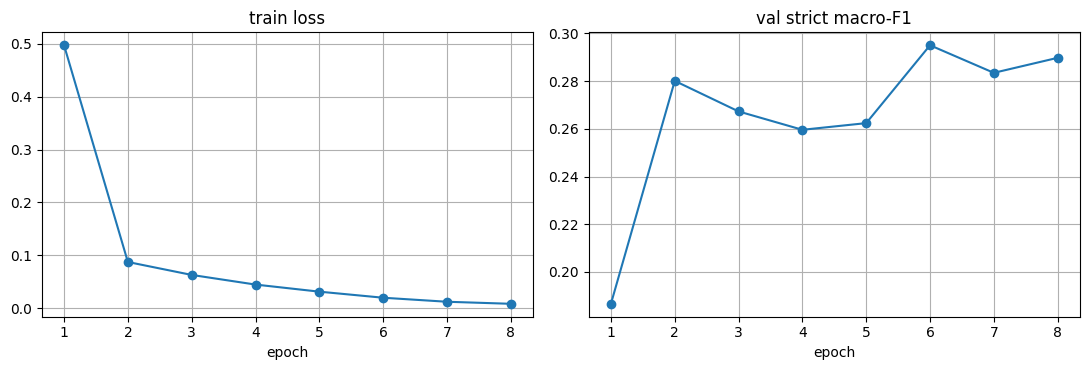

In [10]:
val_preds = ner_lib.predict_docs(model, val_docs, labels, WIN_LEN, WIN_LEN // 2, BATCH, device, amp)
val_gold = {d.doc_id: d.gold for d in val_docs}
sc = ner_lib.strict_scores(val_gold, val_preds, labels)
ner_lib.print_scores(sc)
print("\nerror breakdown (counts):")
for k, v in ner_lib.error_breakdown(val_gold, val_preds).most_common():
    print(f"  {k:36s} {v}")

tot, tr = ner_lib.count_params(model)
tps = ner_lib.benchmark(model, WIN_LEN, BATCH, device, amp)
print(f"\nSUMMARY  method={METHOD} backbone={BACKBONE_ARCH} | task-model params {tot / 1e6:.1f}M | trainable {tr / 1e6:.3f}M "
      f"({100 * tr / tot:.2f}%) | train {TRAIN_MIN:.1f} min | inference {tps:,.0f} tok/s | val strict macro-F1 {sc['macro_f1']:.4f}")
json.dump(dict(method=METHOD, backbone=BACKBONE_ARCH, val=sc, history=history, params_total=tot, params_trainable=tr,
               train_min=TRAIN_MIN, infer_tok_per_s=tps, mcfg=MCFG), open(WORK / "results.json", "w"), indent=1, default=float)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot([h["epoch"] for h in history], [h["train_loss"] for h in history], "o-"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch"); ax[0].grid(True)
ax[1].plot([h["epoch"] for h in history], [h.get("val_macro_f1", 0) for h in history], "o-"); ax[1].set_title("val strict macro-F1"); ax[1].set_xlabel("epoch"); ax[1].grid(True)
plt.tight_layout(); plt.savefig(WORK / "curves.png", dpi=150); plt.show()

## 10. Test predictions (fold3) -> `submission.zip`

In [11]:
# ---- official test documents (fold3) -> prediction.json -> submission.zip
raw3 = json.load(open(fetch("fold3-text.json"), encoding="utf-8"))
test_texts = ner_lib.parse_texts(raw3)
test_docs = [ner_lib.build_doc(k, t, [], tokenizer, label2id, NORMALIZE_WHITESPACE) for k, t in test_texts.items()]
test_preds = ner_lib.predict_docs(model, test_docs, labels, WIN_LEN, WIN_LEN // 2, BATCH, device, amp)
out = ner_lib.write_prediction(test_preds, list(test_texts), WORK / "prediction.json", WORK / "submission.zip")

# sanity checks the evaluator also performs
assert set(out) == set(test_texts), "doc IDs differ from official test IDs"
bad = [(k, s, e) for k, v in out.items() for s, e, l in v if not (0 <= s < e <= len(test_texts[k])) or l not in label2id]
assert not bad, f"invalid spans: {bad[:5]}"
from collections import Counter
n_ent = sum(len(v) for v in out.values())
print(f"{len(out)} docs | {n_ent} predicted entities ({n_ent / len(out):.1f} per doc) | label counts:",
      dict(Counter(l for v in out.values() for _, _, l in v)))
d0 = test_docs[0]; s, e, l = out[d0.doc_id][0] if out[d0.doc_id] else (0, 0, "-")
print("example:", l, "->", repr(test_texts[d0.doc_id][s:e]))
print("submission:", WORK / "submission.zip")

fold3-text.json:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

35 docs | 5247 predicted entities (149.9 per doc) | label counts: {'COURT': 630, 'CASENO': 463, 'APP': 207, 'RESP': 135, 'JUDGE': 150, 'DATE': 790, 'AUTH': 513, 'STAT': 962, 'PREC': 1004, 'A.COUNSEL': 114, 'R.COUNSEL': 128, 'WIT': 151}
example: COURT -> 'SUPREME'
submission: /kaggle/working/cs781_phase2_adapter_mla/submission.zip


## 11. Export (use as teacher in the distillation notebook)

In [12]:
meta = dict(method=METHOD, arch=BACKBONE_ARCH, backbone_cfg=bcfg_used, method_cfg=MCFG, labels=labels, echo=ECHO, win_len=WIN_LEN,
            normalize=NORMALIZE_WHITESPACE, tokenizer_hash=ner_lib.file_hash(export_dir / "tokenizer.json"),
            val_macro_f1=best_f1)
extra = ["ner_lib.py"] + ([f"peft_{METHOD}.py"] if METHOD != "full" else [])
EXPORT_DIR = ner_lib.export_ner(model, WORK / f"ner_export_{METHOD}_{BACKBONE_ARCH}", meta,
                                arch_file=export_dir / "legal_arch.py", tokenizer_file=export_dir / "tokenizer.json", extra_files=extra)
print("exported ->", EXPORT_DIR, "(this folder can be used as the teacher in the knowledge-distillation notebook)")

exported -> /kaggle/working/cs781_phase2_adapter_mla/ner_export_adapter_mla (this folder can be used as the teacher in the knowledge-distillation notebook)
